In [2]:
import xarray as xr
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import glob
from pathlib import Path

import sys
# Ensure local scripts are importable
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.paths import ProjectPaths
from scripts.mapping_config import MappingConfig

# Configure display
%matplotlib inline

In [3]:
# Resolve the GEBCO file path
gebco_file = next(ProjectPaths.BATHYMETRY_GEBCO_DIR.glob("*.nc"))
ds_gebco = xr.open_dataset(gebco_file)

# Convert to a Plottable Grid
# Latitude and Longitude are 1D arrays; Elevation is 2D
lon_g = ds_gebco.lon.values
lat_g = ds_gebco.lat.values
# Elevation is usually negative for seafloor; convert to Depth (positive)
depth_g = -ds_gebco.elevation.values

print(f"GEBCO Grid Loaded: {depth_g.shape}")
print(f"Longitudes: {lon_g.min():.2f} to {lon_g.max():.2f}")
print(f"Latitudes: {lat_g.min():.2f} to {lat_g.max():.2f}")


GEBCO Grid Loaded: (668, 1517)
Longitudes: 129.86 to 136.18
Latitudes: 32.33 to 35.11


In [4]:
jodc_files = list(ProjectPaths.BATHYMETRY_JODC_DIR.glob("mesh500_*.txt"))
jodc_list = []

print(f"Loading {len(jodc_files)} JODC mesh files...")
for f in jodc_files:
    # Space-separated values
    df = pd.read_csv(f, sep='\s+', names=['type', 'lat', 'lon', 'depth'], header=None)
    jodc_list.append(df)

df_jodc = pd.concat(jodc_list, ignore_index=True)

# Create GeoDataFrame
gdf_jodc = gpd.GeoDataFrame(
    df_jodc, 
    geometry=gpd.points_from_xy(df_jodc.lon, df_jodc.lat),
    crs="EPSG:4326"
)

# Filters: Type==1 usually denotes valid water points in JODC mesh systems
gdf_jodc = gdf_jodc[gdf_jodc['type'] == 1].reset_index(drop=True)

print(f"JODC Data Loaded: {len(gdf_jodc)} points.")


Loading 13 JODC mesh files...
JODC Data Loaded: 105057 points.


In [5]:
# Map styling setup

def setup_sis_map(ax):
    """Applies standardized SIS background, land, and gridlines according to SIS_mapping_standard.md."""
    # 1. Background (Ocean)
    ax.set_facecolor(MappingConfig.COLOR_OCEAN)
    
    # 2. Land Boundary (High-resolution Setonaikai Prefecture shapefile)
    land_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Setonaikai_boundary.shp"
    sis_land = gpd.read_file(land_path).to_crs("EPSG:4326")
    sis_land.plot(
        ax=ax, 
        facecolor=MappingConfig.COLOR_LAND, 
        edgecolor=MappingConfig.COLOR_LAND_EDGE,
        linewidth=MappingConfig.LINEWIDTH_LAND,
        zorder=MappingConfig.ZORDER_LAND,
        transform=ccrs.PlateCarree()
    )
    
    # 3. Gridlines
    gl = ax.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.5, zorder=MappingConfig.ZORDER_GRIDLINES)
    gl.top_labels = False
    gl.right_labels = False
    return gl

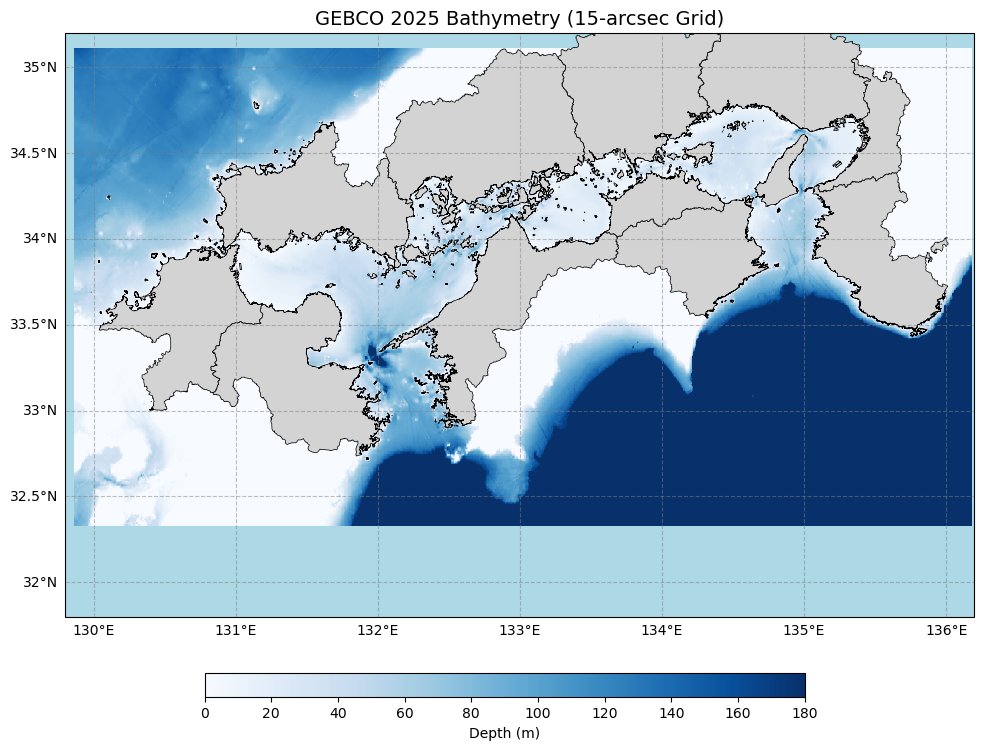

In [6]:
fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.PlateCarree()})
setup_sis_map(ax)

# Plot GEBCO Grid
im_gebco = ax.pcolormesh(
    lon_g, lat_g, depth_g, 
    cmap='Blues', vmin=0, vmax=180, 
    transform=ccrs.PlateCarree(),
    zorder=0.5  # <--- Change this from MappingConfig.ZORDER_PREDICTED
)

ax.set_title("GEBCO 2025 Bathymetry (15-arcsec Grid)", fontsize=14)

# Standardized Colorbar Axis
cbar_ax = fig.add_axes([0.25, 0.05, 0.5, 0.03]) 
cbar = fig.colorbar(im_gebco, cax=cbar_ax, orientation='horizontal', label='Depth (m)')

# Set Extent (with 0.2 buffer)
bounds = gdf_jodc.total_bounds
ax.set_extent([bounds[0]-0.2, bounds[2]+0.2, bounds[1]-0.2, bounds[3]+0.2], crs=ccrs.PlateCarree())

plt.subplots_adjust(bottom=0.15)
plt.show()


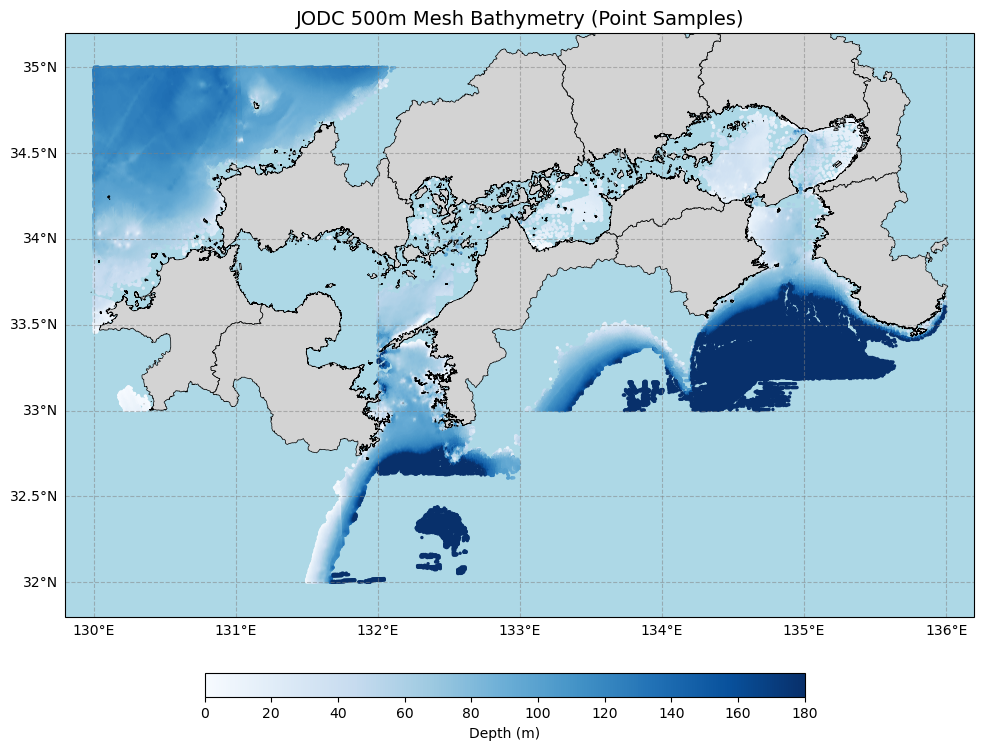

In [7]:
fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.PlateCarree()})
setup_sis_map(ax)

# Plot JODC Points
sc_jodc = ax.scatter(
    gdf_jodc.lon, gdf_jodc.lat, c=gdf_jodc.depth, 
    s=2, cmap='Blues', vmin=0, vmax=180, 
    transform=ccrs.PlateCarree(), 
    zorder=0.5  # <--- Change this from MappingConfig.ZORDER_PREDICTED
)

ax.set_title("JODC 500m Mesh Bathymetry (Point Samples)", fontsize=14)

# Standardized Colorbar Axis
cbar_ax = fig.add_axes([0.25, 0.05, 0.5, 0.03]) 
cbar = fig.colorbar(sc_jodc, cax=cbar_ax, orientation='horizontal', label='Depth (m)')

# Set Extent
ax.set_extent([bounds[0]-0.2, bounds[2]+0.2, bounds[1]-0.2, bounds[3]+0.2], crs=ccrs.PlateCarree())

plt.subplots_adjust(bottom=0.15)
plt.show()


### Plot the decorrelation scale results onto the bathymetry map

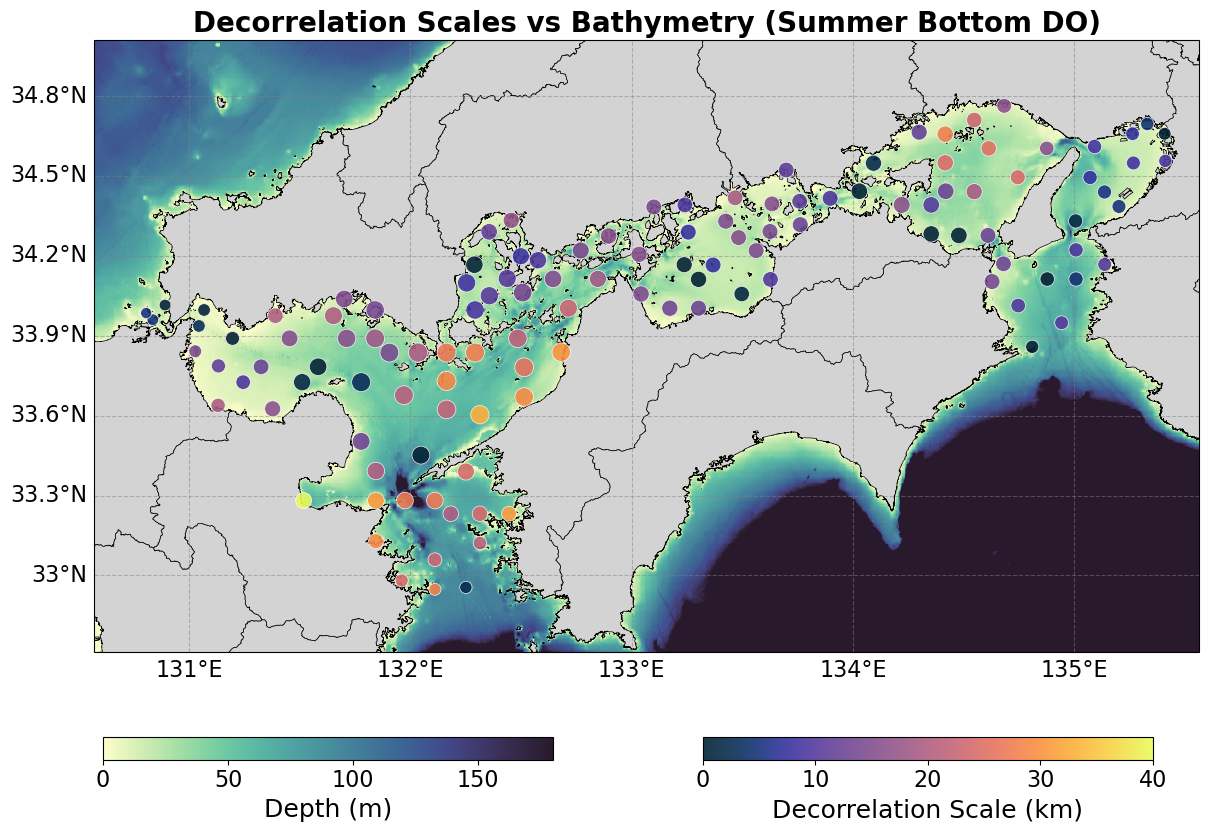

In [16]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cmocean
from scripts.paths import ProjectPaths
from scripts.mapping_config import MappingConfig

# Apply the global project style as per SIS Mapping Standard
plt.style.use('../project_style.mplstyle')

# 1. Load Decorrelation Results
subset_dir = ProjectPaths.get_subset_dir('Summer', 'bottom')
decorrelation_file = subset_dir / "stations_decorrelation_scale.csv"
df_decorr = pd.read_csv(decorrelation_file, dtype={'Station_ID': str})
df_decorr['Station_ID'] = df_decorr['Station_ID'].str.zfill(8)

# 2. Match with Coordinates
gdf_main = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)
gdf_stations = gdf_main[['zettaicode', 'latitude', 'longitude']].drop_duplicates(subset='zettaicode')
gdf_stations = gdf_stations.rename(columns={'zettaicode': 'Station_ID'})
gdf_stations['Station_ID'] = gdf_stations['Station_ID'].astype(str).str.zfill(8)

df_plot = df_decorr.merge(gdf_stations, on='Station_ID', how='inner')

# 3. Get Standard Map Extents (from SIS water mask)
water_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS water mass polygon" / "sea_area_mask_simplified.shp"
sis_water = gpd.read_file(water_boundary_path).to_crs("EPSG:4326")
bounds = sis_water.total_bounds
# [xmin, xmax, ymin, ymax] for Cartopy
extent = [bounds[0]+0.1, bounds[2]+0.1, bounds[1]-0, bounds[3]+0.2]

# 4. Initialize Plot
# Calculate dynamic height based on geographic extent to remove excess vertical white space
width_deg = extent[1] - extent[0]
height_deg = extent[3] - extent[2]
aspect_ratio = height_deg / width_deg
fig_width = 15
# Map height (approx 6.9") + 2.1" buffer for title and colorbars
fig_height = (fig_width * aspect_ratio) + 2.1 

fig, ax = plt.subplots(figsize=(fig_width, fig_height), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_facecolor(MappingConfig.COLOR_OCEAN) 

# --- Z-ORDER 0.5: BATHYMETRY ---
im_gebco = ax.pcolormesh(
    lon_g, lat_g, depth_g, 
    cmap=cmocean.cm.deep,
    vmin=0, vmax=180, 
    transform=ccrs.PlateCarree(),
    zorder=0.5
)

# --- Z-ORDER 1: LAND MASK ---
land_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Setonaikai_boundary_2.shp"
sis_land = gpd.read_file(land_path).to_crs("EPSG:4326")
sis_land.plot(
    ax=ax, facecolor=MappingConfig.COLOR_LAND, edgecolor=MappingConfig.COLOR_LAND_EDGE,
    linewidth=MappingConfig.LINEWIDTH_LAND, zorder=MappingConfig.ZORDER_LAND,
    transform=ccrs.PlateCarree()
)

# --- Z-ORDER 2: GRIDLINES ---
gl = ax.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.5, zorder=MappingConfig.ZORDER_GRIDLINES)
gl.top_labels = False
gl.right_labels = False
# SIS Standard: Tick Labels = 16
gl.xlabel_style = {'size': 16}
gl.ylabel_style = {'size': 16}

# --- Z-ORDER 5: DECORRELATION DATA OVERLAY ---
sc = ax.scatter(
    df_plot.longitude, df_plot.latitude, 
    c=df_plot.Decorrelation_Scale_km, 
    s=df_plot.n_neighbors_100km * 3, 
    cmap=cmocean.cm.thermal,
    vmin=0, vmax=40, 
    alpha=0.9, edgecolors='white', linewidths=0.5,
    transform=ccrs.PlateCarree(), 
    zorder=MappingConfig.ZORDER_OBSERVATIONS
)

ax.set_extent(extent, crs=ccrs.PlateCarree())
# SIS Standard: Title = 20, Bold
ax.set_title("Decorrelation Scales vs Bathymetry (Summer Bottom DO)", fontsize=20, fontweight='bold')

# 5. Add Two Colorbars
# Subplots adjust to minimize space; bottom margin reduced to pull colorbars up
plt.subplots_adjust(bottom=0.20)

# Colorbar axes: [left, bottom, width, height]
# SIS Standard: Axis Labels = 18, Tick Labels = 16
cbar_ax_bathy = fig.add_axes([0.15, 0.08, 0.3, 0.025]) 
cb1 = fig.colorbar(im_gebco, cax=cbar_ax_bathy, orientation='horizontal')
cb1.set_label('Depth (m)', fontsize=18)
cb1.ax.tick_params(labelsize=16)

cbar_ax_decorr = fig.add_axes([0.55, 0.08, 0.3, 0.025]) 
cb2 = fig.colorbar(sc, cax=cbar_ax_decorr, orientation='horizontal')
cb2.set_label('Decorrelation Scale (km)', fontsize=18)
cb2.ax.tick_params(labelsize=16)

plt.show()
